# 04 — Évaluation des modèles sur HAM10000

**Projet :** classification de sept catégories de lésions cutanées avec ResNet50, EfficientNet-B0 et ViT-B/16.

**Objectif du notebook :** évalue les trois architectures fine-tunées dans `03_ModelsTraining.ipynb` : **ResNet50**, **EfficientNet-B0** et **ViT-B/16**. Nous utilisons uniquement le **Test Set indépendant (1 502 images)** défini dans `02_DataPreprocessing.ipynb`.

In [1]:
from pathlib import Path
import json
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Reproductibilité
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. CPU ou GPU
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 3. Dataset HAM10000
DATA_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000"
)

IMAGES_DIR = DATA_DIR / "images"

# 4. Partitions et configuration du notebook 02
PREPROCESSING_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham10000-datasplits/ham10000_Portfolio"
)

SPLITS_DIR = PREPROCESSING_DIR / "splits"
CONFIG_PATH = PREPROCESSING_DIR / "data_config.json"

# 5. Paramètres identiques au notebook 03
CLASSES = [
    "akiec", "bcc", "bkl",
    "df", "mel", "nv", "vasc"
]

CLASS_TO_IDX = {
    classe: i for i, classe in enumerate(CLASSES)
}

IMAGE_SIZE = 224

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 6. Dossier des résultats de l'évaluation
OUTPUT_ROOT = Path(
    "/kaggle/working/ham10000_evaluation"
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# 7. Vérifications
assert DATA_DIR.is_dir(), "Dataset HAM10000 introuvable."
assert IMAGES_DIR.is_dir(), "Images introuvables."
assert CONFIG_PATH.is_file(), "Configuration introuvable."
assert (SPLITS_DIR / "test.csv").is_file(), "Test Set introuvable."

print("PyTorch :", torch.__version__)
print("Device :", DEVICE)
print("Images :", IMAGES_DIR)
print("Partitions :", SPLITS_DIR)
print("Nombre de classes :", len(CLASSES))
print("Configuration initiale réalisée.")

PyTorch : 2.11.0+cu128
Device : cuda
Images : /kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000/images
Partitions : /kaggle/input/datasets/imaneelqoraychy/ham10000-datasplits/ham10000_Portfolio/splits
Nombre de classes : 7
Configuration initiale réalisée.


### 1.1. Localisation des meilleurs checkpoints

Les trois fichiers `.pt` sont récupérés directement dans les **outputs Kaggle du notebook 03** :

- `resnet50_best.pt` ;
- `efficientnet_b0_best.pt` ;
- `vit_b_16_best.pt`.

In [2]:
# 1. Dossier contenant les modèles entraînés
MODELS_DIR = Path(
    "/kaggle/input/notebooks/imaneelqoraychy/03-modelstraining/ham10000_Portfolio/models"
)

# 2. Chemins des trois checkpoints
MODEL_PATHS = {
    "resnet50": MODELS_DIR / "resnet50_best.pt",
    "efficientnet_b0": MODELS_DIR / "efficientnet_b0_best.pt",
    "vit_b_16": MODELS_DIR / "vit_b_16_best.pt"
}

# 3. Vérifier les trois fichiers
for architecture, path in MODEL_PATHS.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"Checkpoint introuvable : {path}"
        )

    print(f"{architecture} : OK")
    print("Chemin :", path)
    print()

print("Les trois checkpoints sont disponibles.")


resnet50 : OK
Chemin : /kaggle/input/notebooks/imaneelqoraychy/03-modelstraining/ham10000_Portfolio/models/resnet50_best.pt

efficientnet_b0 : OK
Chemin : /kaggle/input/notebooks/imaneelqoraychy/03-modelstraining/ham10000_Portfolio/models/efficientnet_b0_best.pt

vit_b_16 : OK
Chemin : /kaggle/input/notebooks/imaneelqoraychy/03-modelstraining/ham10000_Portfolio/models/vit_b_16_best.pt

Les trois checkpoints sont disponibles.


## 2. Chargement et vérification des partitions

In [3]:
# 1. Charger les métadonnées et la configuration
metadata = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = json.load(file)

# Vérifier les classes
assert config["classes"] == CLASSES
assert config["class_to_idx"] == CLASS_TO_IDX

# 2. Charger les trois partitions
parts = {}

for name in ["train", "val", "test"]:

    frame = pd.read_csv(SPLITS_DIR / f"{name}.csv")

    # Vérifier les colonnes et les labels
    assert {"image_id", "lesion_id", "dx", "label"}.issubset(frame.columns)
    assert frame["image_id"].is_unique
    assert (
        frame["label"] == frame["dx"].map(CLASS_TO_IDX)
    ).all()

    # Construire les chemins des images
    frame["image_path"] = frame["image_id"].apply(
        lambda image_id: str(IMAGES_DIR / f"{image_id}.jpg")
    )

    parts[name] = frame

    print(
        f"{name} : {len(frame)} images, "
        f"{frame['lesion_id'].nunique()} lésions"
    )

# 3. Vérifier l'absence de Data Leakage
for first, second in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    assert set(parts[first]["lesion_id"]).isdisjoint(
        parts[second]["lesion_id"]
    )

    assert set(parts[first]["image_id"]).isdisjoint(
        parts[second]["image_id"]
    )

# Vérifier la couverture du dataset
all_ids = set().union(
    *(set(frame["image_id"]) for frame in parts.values())
)

assert all_ids == set(metadata["image_id"])

print("\nAucune fuite de données : OK")

# 4. Vérifier les Class Weights du notebook 02
counts = np.bincount(
    parts["train"]["label"].to_numpy(dtype=int),
    minlength=len(CLASSES)
)

assert (counts > 0).all()

expected_weights = len(parts["train"]) / (len(CLASSES) * counts)

saved_weights = np.array([
    config["class_weights_train_only"][c]
    for c in CLASSES
])

assert np.allclose(
    expected_weights,
    saved_weights,
    rtol=1e-6
)

print("Class Weights : OK")

# 5. Calculer la signature du Train Set
train_ids = sorted(parts["train"]["image_id"].astype(str))

train_signature = hashlib.sha256(
    "|".join(train_ids).encode()
).hexdigest()

print("Signature Train :", train_signature[:16])

# 6. Vérifications finales
assert len(parts["test"]) == 1502
assert Path(parts["test"].iloc[0]["image_path"]).is_file()

print("Test Set :", len(parts["test"]), "images")
print("Chargement des partitions : OK")

train : 7012 images, 5229 lésions
val : 1501 images, 1120 lésions
test : 1502 images, 1121 lésions

Aucune fuite de données : OK
Class Weights : OK
Signature Train : a28bdeff87aac360
Test Set : 1502 images
Chargement des partitions : OK


## 3. Préparation du Dataset et reconstruction des modèles

### 3.1. Transformations d'évaluation

Les images Test sont converties en RGB, redimensionnées à **224 × 224**, transformées en tenseurs, puis normalisées avec les moyennes et écarts-types d'ImageNet.

Contrairement à Train, **aucune augmentation aléatoire** (retournement, variation de luminosité, etc.) n'est appliquée pendant l'évaluation. Le premier échantillon contrôlé appartient à la classe `mel` (indice `4`).

In [4]:
class HAM10000Dataset(Dataset):

    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True)

        # Prétraitements communs aux trois modèles
        augmentations = []

        if training:
            augmentations = [
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomVerticalFlip(p=0.5),
                transforms.ColorJitter(
                    brightness=0.05,
                    contrast=0.05
                )
            ]

        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            *augmentations,
            transforms.ToTensor(),
            transforms.Normalize(mean=MEAN, std=STD)
        ])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):

        row = self.frame.iloc[idx]

        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = int(row["label"])

        return image, label


# Vérification sur une image du Test Set
test_dataset = HAM10000Dataset(
    parts["test"],
    training=False
)

image, label = test_dataset[0]

print("Images Test :", len(test_dataset))
print("Dimensions :", image.shape)
print("Label :", label)
print("Classe :", CLASSES[label])
print("Dataset prêt pour l'évaluation.")

Images Test : 1502
Dimensions : torch.Size([3, 224, 224])
Label : 4
Classe : mel
Dataset prêt pour l'évaluation.


### 3.2. Reconstruction et chargement des architectures
Nous recréons les trois architectures avec leur tête de classification à **sept sorties**. La reconstruction utilise `weights=None` pour éviter un téléchargement ImageNet inutile : les paramètres finement ajustés sont ensuite restaurés depuis `state_dict`.

Pour chaque checkpoint, les vérifications portent sur :

- l'architecture déclarée ;
- l'ordre des sept classes ;
- la taille d'entrée `224 × 224` ;
- la signature du Train Set.

In [5]:
# Versions ImageNet utilisées pendant le Fine-Tuning
WEIGHT_VERSION = {
    "resnet50": "IMAGENET1K_V2",
    "efficientnet_b0": "IMAGENET1K_V1",
    "vit_b_16": "IMAGENET1K_V1"
}


def build_model(architecture, pretrained=False):

    # 1. ResNet50
    if architecture == "resnet50":
        weights = (
            models.ResNet50_Weights.IMAGENET1K_V2
            if pretrained else None
        )

        model = models.resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
        head = model.fc

    # 2. EfficientNet-B0
    elif architecture == "efficientnet_b0":
        weights = (
            models.EfficientNet_B0_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        model = models.efficientnet_b0(weights=weights)
        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features,
            len(CLASSES)
        )
        head = model.classifier[-1]

    # 3. Vision Transformer
    elif architecture == "vit_b_16":
        weights = (
            models.ViT_B_16_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        model = models.vit_b_16(weights=weights)
        model.heads.head = nn.Linear(
            model.heads.head.in_features,
            len(CLASSES)
        )
        head = model.heads.head

    else:
        raise ValueError(f"Architecture inconnue : {architecture}")

    return model, head


def load_checkpoint_model(architecture):

    # 4. Retrouver le checkpoint déjà vérifié
    checkpoint_path = MODEL_PATHS[architecture]

    # Charger les poids sur CPU
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    # 5. Vérifier la compatibilité
    if checkpoint["architecture"] != architecture:
        raise ValueError("Architecture incompatible.")

    if checkpoint["classes"] != CLASSES:
        raise ValueError("Classes incompatibles.")

    if checkpoint["image_size"] != IMAGE_SIZE:
        raise ValueError("Taille d'image incompatible.")

    if checkpoint["train_signature"] != train_signature:
        raise ValueError("Partitions Train incompatibles.")

    # 6. Reconstruire sans téléchargement ImageNet
    model, _ = build_model(
        architecture,
        pretrained=False
    )

    # Charger les poids fine-tunés
    model.load_state_dict(
        checkpoint["state_dict"],
        strict=True
    )

    # 7. Passer en mode évaluation
    model = model.to(DEVICE)
    model.eval()

    return model, checkpoint, checkpoint_path


print("Architectures configurées :", list(WEIGHT_VERSION))
print("Fonction de chargement des checkpoints.")

Architectures configurées : ['resnet50', 'efficientnet_b0', 'vit_b_16']
Fonction de chargement des checkpoints.


## 4. Sélection du modèle sur Validation

In [6]:
# 1. Architectures à comparer
ARCHITECTURES = [
    "resnet50",
    "efficientnet_b0",
    "vit_b_16"
]

checkpoint_info = {}

# 2. Lire les informations de chaque checkpoint
for architecture in ARCHITECTURES:

    checkpoint = torch.load(
        MODEL_PATHS[architecture],
        map_location="cpu",
        weights_only=True
    )

    # Vérifier la compatibilité avec notre projet
    assert checkpoint["architecture"] == architecture
    assert checkpoint["classes"] == CLASSES
    assert checkpoint["image_size"] == IMAGE_SIZE
    assert checkpoint["train_signature"] == train_signature

    # Enregistrer les résultats de validation
    checkpoint_info[architecture] = {
        "architecture": architecture,
        "best_val_macro_f1": float(checkpoint["best_val_macro_f1"]),
        "best_val_loss": float(checkpoint["best_val_loss"]),
        "best_epoch": int(checkpoint["best_epoch"])
    }

    print(f"{architecture} : checkpoint vérifié")

    # Libérer les poids chargés
    del checkpoint

# 3. Construire le tableau de comparaison
validation_ranking = pd.DataFrame(
    checkpoint_info.values()
)

# Classer selon le meilleur macro-F1
validation_ranking = validation_ranking.sort_values(
    ["best_val_macro_f1", "best_val_loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(validation_ranking)

# 4. Sélectionner le meilleur modèle sur Validation
selected_arch = validation_ranking.iloc[0]["architecture"]

print("\nMeilleur modèle sur Validation :", selected_arch)
print(
    "Macro-F1 :",
    round(validation_ranking.iloc[0]["best_val_macro_f1"] * 100, 2),
    "%"
)

resnet50 : checkpoint vérifié
efficientnet_b0 : checkpoint vérifié
vit_b_16 : checkpoint vérifié


,architecture,best_val_macro_f1,best_val_loss,best_epoch
0,vit_b_16,0.785512,0.578952,11
1,efficientnet_b0,0.707474,0.564720,22
2,resnet50,0.707088,0.559246,16



Meilleur modèle sur Validation : vit_b_16
Macro-F1 : 78.55 %


Les checkpoints enregistrent le **meilleur macro-F1 de validation**, la perte correspondante et l'époque sélectionnée. Le classement ci-dessous provient exclusivement de Validation :

| Architecture | Meilleur macro-F1 validation | Meilleure époque |
|---|---:|---:|
| **ViT-B/16** | **78,55 %** | **11** |
| EfficientNet-B0 | 70,75 % | 22 |
| ResNet50 | 70,71 % | 16 |

**ViT-B/16 est sélectionné avant l'évaluation Test.** Les résultats sur Test serviront à décrire les forces et faiblesses de chaque réseau, et non à modifier rétroactivement ce choix.

## 5. Évaluation sur le Test Set

### 5.1. Fonction de prédiction

La fonction `score_predictions()` parcourt les **1 502 images Test** sans augmentation, dans un ordre fixe (`shuffle=False`), avec `torch.inference_mode()`.

Les métriques calculées sont :

- **Accuracy** : proportion globale de prédictions correctes .
- **Macro-F1** : moyenne des F1-scores des sept classes, sans privilégier la classe majoritaire.
- **Balanced accuracy** : moyenne des recalls par classe.
- **Recall mélanome (`mel`)** : proportion des vrais mélanomes correctement reconnus.

In [7]:
def score_predictions(frame, architecture, checkpoint_path, model):

    # 1. Préparer les images sans Data Augmentation
    dataset = HAM10000Dataset(frame, training=False)

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0
    )

    # 2. Préparer les résultats
    y_true = []
    y_pred = []
    probabilities = []

    model.eval()

    # 3. Effectuer les prédictions sans gradients
    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(DEVICE)

            outputs = model(images)

            # Transformer les scores en probabilités
            probs = torch.softmax(outputs.float(), dim=1)
            probs = probs.cpu().numpy()

            probabilities.extend(probs.tolist())
            y_pred.extend(probs.argmax(axis=1).tolist())
            y_true.extend(labels.tolist())

    # 4. Vérifier le nombre de prédictions
    assert len(y_true) == len(frame)

    # 5. Construire le tableau des prédictions
    predictions = frame[
        ["image_id", "lesion_id", "dx", "label"]
    ].copy().reset_index(drop=True)

    predictions["prediction_idx"] = y_pred
    predictions["predicted_dx"] = [
        CLASSES[i] for i in y_pred
    ]

    predictions["confidence"] = [
        max(p) for p in probabilities
    ]

    # Probabilité attribuée à chaque classe
    for i, classe in enumerate(CLASSES):
        predictions[f"p_{classe}"] = [
            p[i] for p in probabilities
        ]

    # 6. Calculer les métriques
    y_true_array = np.array(y_true)
    y_pred_array = np.array(y_pred)

    mel_mask = y_true_array == CLASS_TO_IDX["mel"]

    mel_recall = (
        (y_pred_array[mel_mask] == CLASS_TO_IDX["mel"]).mean()
    )

    metrics = {
        "architecture": architecture,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=list(range(len(CLASSES))),
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "mel_recall": float(mel_recall)
    }

    return predictions, metrics, y_true, y_pred


print("Fonction score_predictions() définie avec succès.")

Fonction score_predictions() définie avec succès.


### 5.2. Évaluation des trois architectures et export des résultats


===== ÉVALUATION : resnet50 =====


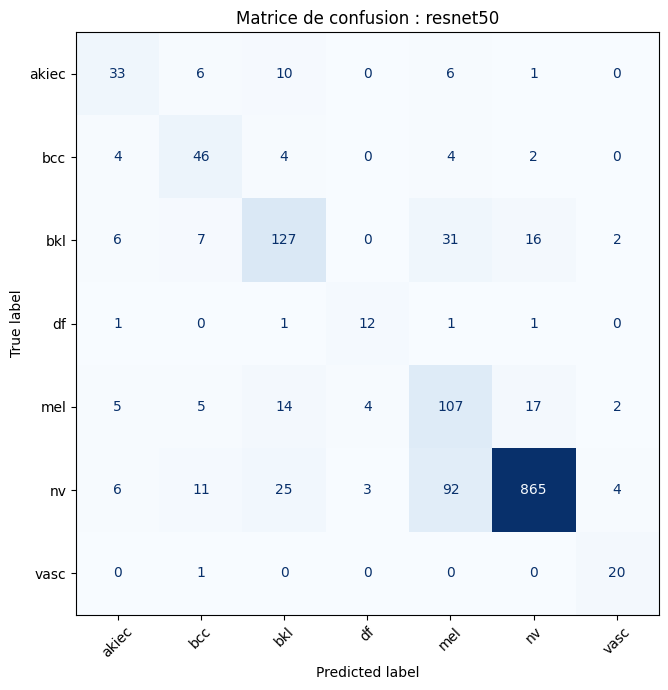

Accuracy : 0.8056
Macro-F1 : 0.7012
Balanced Accuracy : 0.7550
Recall Mélanome : 0.6948

===== ÉVALUATION : efficientnet_b0 =====


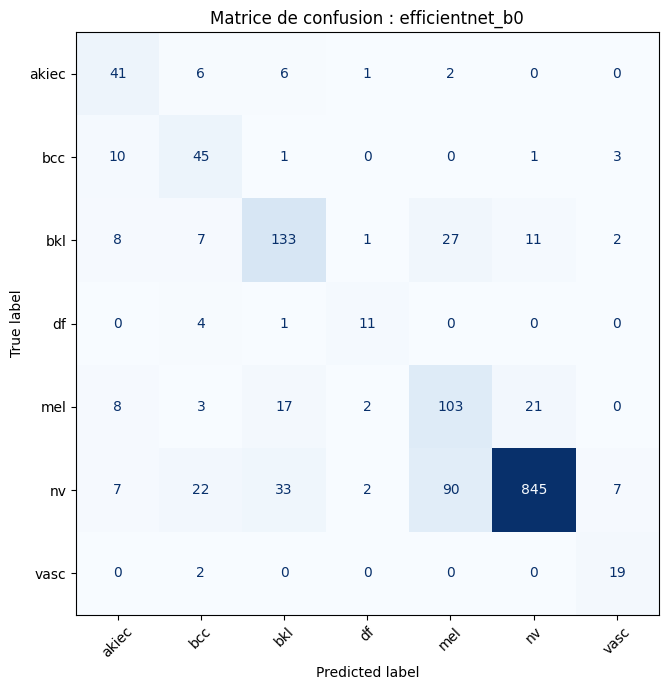

Accuracy : 0.7969
Macro-F1 : 0.6824
Balanced Accuracy : 0.7553
Recall Mélanome : 0.6688

===== ÉVALUATION : vit_b_16 =====


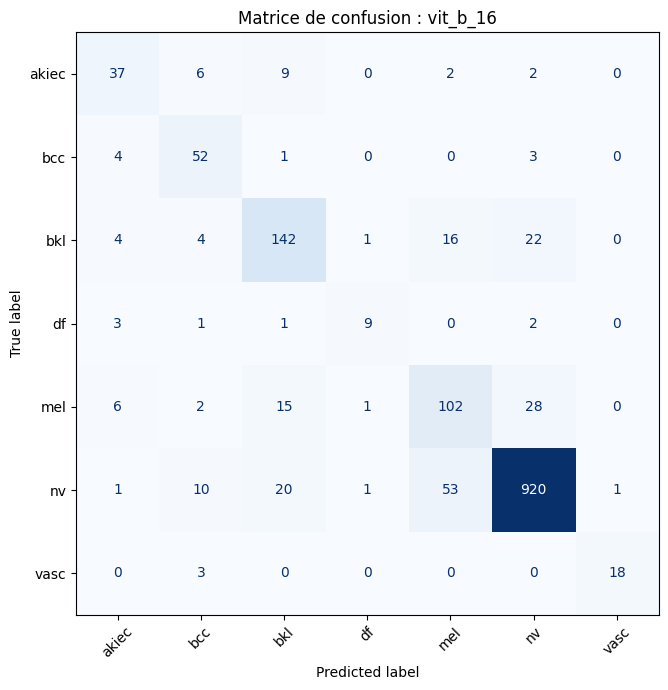

Accuracy : 0.8522
Macro-F1 : 0.7526
Balanced Accuracy : 0.7536
Recall Mélanome : 0.6623

===== COMPARAISON FINALE =====


,architecture,accuracy,macro_f1,balanced_accuracy,mel_recall,best_val_macro_f1,selected_on_validation
2,vit_b_16,0.852197,0.752600,0.753600,0.662338,0.785512,True
1,efficientnet_b0,0.796937,0.682447,0.755271,0.668831,0.707474,False
0,resnet50,0.805593,0.701153,0.754991,0.694805,0.707088,False



Évaluation des trois modèles terminée.


In [8]:
import gc

# 1. Préparer les dossiers des résultats
METRIC_DIR = OUTPUT_ROOT / "metrics"
FIG_DIR = OUTPUT_ROOT / "figures"

METRIC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

results = []

# 2. Évaluer les trois modèles successivement
for architecture in ARCHITECTURES:

    print(f"\n===== ÉVALUATION : {architecture} =====", flush=True)

    # Charger le meilleur checkpoint
    model, checkpoint, checkpoint_path = load_checkpoint_model(
        architecture
    )

    # Vérifier la signature du Train Set
    assert checkpoint["train_signature"] == train_signature

    # Effectuer les prédictions sur le Test Set
    predictions, metrics, y_true, y_pred = score_predictions(
        parts["test"],
        architecture,
        checkpoint_path,
        model
    )

    # Ajouter les informations de Validation
    metrics["best_val_macro_f1"] = checkpoint_info[
        architecture
    ]["best_val_macro_f1"]

    metrics["selected_on_validation"] = (
        architecture == selected_arch
    )

    results.append(metrics)

    # 3. Sauvegarder les prédictions
    predictions.to_csv(
        METRIC_DIR / f"predictions_{architecture}.csv",
        index=False
    )

    # 4. Rapport de classification par classe
    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        zero_division=0,
        output_dict=True
    )

    pd.DataFrame(report).T.to_csv(
        METRIC_DIR / f"classification_report_{architecture}.csv"
    )

    # 5. Matrice de confusion
    fig, ax = plt.subplots(figsize=(8, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=list(range(len(CLASSES))),
        display_labels=CLASSES,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"Matrice de confusion : {architecture}")

    plt.tight_layout()

    fig.savefig(
        FIG_DIR / f"confusion_{architecture}.png",
        dpi=190
    )

    plt.show()
    plt.close(fig)

    # 6. Afficher les résultats du modèle
    print(f"Accuracy : {metrics['accuracy']:.4f}")
    print(f"Macro-F1 : {metrics['macro_f1']:.4f}")
    print(
        f"Balanced Accuracy : "
        f"{metrics['balanced_accuracy']:.4f}"
    )
    print(f"Recall Mélanome : {metrics['mel_recall']:.4f}")

    # 7. Libérer la mémoire avant le modèle suivant
    del model, checkpoint
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# 8. Construire et sauvegarder la comparaison finale
test_comparison = pd.DataFrame(results)

test_comparison.to_csv(
    METRIC_DIR / "test_comparison.csv",
    index=False
)

print("\n===== COMPARAISON FINALE =====")

display(
    test_comparison.sort_values(
        "best_val_macro_f1",
        ascending=False
    )
)

print("\nÉvaluation des trois modèles terminée.")

## 6. Export du modèle sélectionné

In [9]:
# 1. Préparer les informations de sélection
selected = {
    "selected_architecture": selected_arch,
    "selection_metric": "validation_macro_f1",
    "train_signature": train_signature,
    "classes": CLASSES,
    "validation_ranking": [
        {
            "architecture": row.architecture,
            "best_val_macro_f1": float(row.best_val_macro_f1),
            "best_val_loss": float(row.best_val_loss),
            "best_epoch": int(row.best_epoch)
        }
        for row in validation_ranking.itertuples(index=False)
    ]
}

# 2. Sauvegarder la sélection dans un fichier JSON
selected_path = METRIC_DIR / "selected_model.json"

with open(selected_path, "w", encoding="utf-8") as file:
    json.dump(selected, file, indent=2, ensure_ascii=False)

# 3. Vérifier le résultat
print("Modèle sélectionné :", selected_arch)
print("Métrique :", selected["selection_metric"])
print("Fichier sauvegardé :", selected_path)

Modèle sélectionné : vit_b_16
Métrique : validation_macro_f1
Fichier sauvegardé : /kaggle/working/ham10000_evaluation/metrics/selected_model.json


## 7. Analyse scientifique des résultats

### 7.1. Performances globales sur Test

Les résultats ci-dessous ont été mesurés sur les **1 502 images du Test Set**:

| Architecture | Accuracy | Macro-F1 | Balanced accuracy | Recall mélanome |
|---|---:|---:|---:|---:|
| ResNet50 | 80,56 % | 70,12 % | 75,50 % | **69,48 %** |
| EfficientNet-B0 | 79,69 % | 68,24 % | **75,53 %** | 66,88 % |
| **ViT-B/16** | **85,22 %** | **75,26 %** | 75,36 % | 66,23 % |

**ViT-B/16** conserve son avantage sur les métriques globales d'accuracy et de macro-F1. **EfficientNet-B0** présente la meilleure balanced accuracy, mais de très peu devant ResNet50 (environ **0,03 point**).

### 7.2. Analyse spécifique du mélanome

Le Test Set contient **154 images de mélanome (`mel`)**.

| Architecture | Mélanomes reconnus | Mélanomes manqués | Recall |
|---|---:|---:|---:|
| **ResNet50** | **107 / 154** | 47 | **69,48 %** |
| EfficientNet-B0 | 103 / 154 | 51 | 66,88 % |
| ViT-B/16 | 102 / 154 | **59** | 66,23 % |

Malgré sa meilleure performance globale, **ViT-B/16 manque davantage de mélanomes**. Sa matrice de confusion révèle notamment **28 mélanomes prédits comme `nv`**, contre **17 pour ResNet50** et **21 pour EfficientNet-B0**. Cela montre pourquoi l'analyse par pathologie est essentielle lorsque les conséquences des faux négatifs ne sont pas homogènes.

**Interprétation :** ViT-B/16 reste le modèle officiellement sélectionné sur Validation, mais ResNet50 constitue une référence intéressante si l'objectif d'une expérience future est d'améliorer la sensibilité au mélanome. 
### 7.3. Généralisation : Validation contre Test

| Architecture | Meilleur macro-F1 Validation | Macro-F1 Test | Écart Test − Validation |
|---|---:|---:|---:|
| ResNet50 | 70,71 % | 70,12 % | −0,59 point |
| EfficientNet-B0 | 70,75 % | 68,24 % | −2,50 points |
| ViT-B/16 | 78,55 % | 75,26 % | −3,29 points |

Les trois modèles obtiennent des scores Test inférieurs à leurs meilleurs scores Validation. Ces écarts indiquent que la performance du meilleur checkpoint ne se reproduit pas exactement sur un ensemble indépendant, ils peuvent refléter la variabilité entre partitions et les limites de généralisation. Ils ne démontrent pas, à eux seuls, la cause du surapprentissage observé dans les courbes d'entraînement.

### 7.4. Limites de l'étude

- Le jeu HAM10000 est **déséquilibré** : certaines classes sont très peu représentées, ce qui rend leurs estimations de performance plus incertaines.
- Le Test Set est une partition **interne à HAM10000**,  aucune validation externe sur une autre cohorte n'a été réalisée.
- Les erreurs, notamment la confusion entre `mel` et `nv`, nécessitent une analyse ciblée.
- La calibration des probabilités, l'incertitude et les performances selon des sous-groupes n'ont pas encore été examinées.
- **Ces résultats ne constituent pas une validation clinique et ne justifient pas un usage diagnostique autonome.**

### 7.5. Conclusion et suite du projet

**ViT-B/16 reste le modèle sélectionné selon le macro-F1 de validation (78,55 %)** et obtient le meilleur **macro-F1 Test (75,26 %)**. **ResNet50**, bien que moins performant globalement, possède le meilleur **recall du mélanome (69,48 %)** parmi les trois architectures.